# Laboratory 2 homework

In [1]:
!docker compose --progress quiet down --volumes
!docker compose --progress quiet up --detach --wait
!rm -f data/duckdb_trains.db data/late_train.jsonl data/services_2024_duckdb.tsv data/services-2024.json data/services-2024.jsonl data/services-2024.parquet
!rm -f data/homework/homework.db data/homework/services.parquet

In [2]:
import duckdb
import matplotlib.pyplot as plt

db = duckdb.connect("data/homework/homework.db")

## 1. Download data

In [3]:
!mkdir -p data/homework
!wget -nc -q -P data/homework https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv
!wget -nc -q -P data/homework https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv
!for year in $(seq 2011 2023); do wget -nc -q -P data/homework https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-$year.csv; done
!for year in $(seq 2019 2025); do wget -nc -q -P data/homework https://opendata.rijdendetreinen.nl/public/services/services-$year.csv.gz; done
!ls -lh data/homework

total 5441832
-rw-r--r--@ 1 piotrzborowski  staff   400K  6 wrz  2023 disruptions-2011.csv
-rw-r--r--@ 1 piotrzborowski  staff   464K  6 wrz  2023 disruptions-2012.csv
-rw-r--r--@ 1 piotrzborowski  staff   498K  6 wrz  2023 disruptions-2013.csv
-rw-r--r--@ 1 piotrzborowski  staff   531K  6 wrz  2023 disruptions-2014.csv
-rw-r--r--@ 1 piotrzborowski  staff   639K  6 wrz  2023 disruptions-2015.csv
-rw-r--r--@ 1 piotrzborowski  staff   659K  6 wrz  2023 disruptions-2016.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,2M  6 wrz  2023 disruptions-2017.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,5M  6 wrz  2023 disruptions-2018.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,8M  6 wrz  2023 disruptions-2019.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,3M  6 wrz  2023 disruptions-2020.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,4M  6 wrz  2023 disruptions-2021.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,6M  6 wrz  2023 disruptions-2022.csv
-rw-r--r--@ 1 piotrzborowski  staff   1,6M 22 lut  2024 disrup

## 2. Put stations data into `stations` table in DuckDB

In [4]:
db.sql("""
CREATE OR REPLACE TABLE stations AS
FROM "data/homework/stations-2023-09.csv"
""")

db.sql("DESCRIBE stations")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

In [5]:
db.sql("FROM stations LIMIT 5")

┌───────┬─────────┬─────────┬────────────┬──────────────────┬───────────────────────┬──────────────────────┬─────────┬───────────────────────────┬─────────────────┬─────────────────┐
│  id   │  code   │   uic   │ name_short │   name_medium    │       name_long       │         slug         │ country │           type            │     geo_lat     │     geo_lng     │
│ int64 │ varchar │  int64  │  varchar   │     varchar      │        varchar        │       varchar        │ varchar │          varchar          │     double      │     double      │
├───────┼─────────┼─────────┼────────────┼──────────────────┼───────────────────────┼──────────────────────┼─────────┼───────────────────────────┼─────────────────┼─────────────────┤
│   266 │ HT      │ 8400319 │ Den Bosch  │ 's-Hertogenbosch │ 's-Hertogenbosch      │ s-hertogenbosch      │ NL      │ knooppuntIntercitystation │        51.69048 │         5.29362 │
│   269 │ HTO     │ 8400320 │ Dn Bosch O │ 's-Hertogenb. O. │ 's-Hertogenbosch Oost │

## 3. Create tables `distances` and `distances_long`

In [6]:
db.sql("""
CREATE OR REPLACE TABLE distances AS
FROM read_csv("data/homework/tariff-distances-2022-01.csv", nullstr = "XXX")
""")

db.sql("""
CREATE OR REPLACE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS (* EXCLUDE station)
INTO NAME other_station VALUE distance
""")

db.sql("DESCRIBE distances_long")

┌───────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│  column_name  │ column_type │  null   │   key   │ default │  extra  │
│    varchar    │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ other_station │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ distance      │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└───────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [7]:
db.sql("FROM distances_long LIMIT 5")

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
└─────────┴───────────────┴──────────┘

## 4. Put train disruptions into `disruptions` table in the Postgres database

In [8]:
db.sql("INSTALL postgres; LOAD postgres;")

conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres);
""")

db.sql("DROP TABLE IF EXISTS postgres_db.disruptions")

db.sql("""
CREATE TABLE postgres_db.disruptions AS
FROM read_csv("data/homework/disruptions-*.csv", union_by_name = true)
""")

db.sql("SELECT COUNT(*) FROM postgres_db.disruptions")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        49900 │
└──────────────┘

## 5. Transform train services CSV files into a single Parquet file. Make table `services` from it

In [9]:
db.sql("SET preserve_insertion_order = false")

db.sql("""
COPY (FROM read_csv("data/homework/services-*.csv.gz", union_by_name = true))
TO "data/homework/services.parquet" (FORMAT parquet, COMPRESSION zstd)
""")

db.sql("""
CREATE OR REPLACE TABLE services AS
FROM "data/homework/services.parquet"
""")

db.sql("DESCRIBE services")

┌──────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │ column_type │  null   │   key   │ default │  extra  │
│           varchar            │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID               │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Date                 │ DATE        │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Type                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Company              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Train number         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Completely cancelled │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Partly cancelled     │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Maximum delay        │ BIGINT    

In [10]:
db.sql("SELECT COUNT(*) AS num_rows, COUNT(DISTINCT \"Service:RDT-ID\") AS num_services FROM services")

┌───────────┬──────────────┐
│ num_rows  │ num_services │
│   int64   │    int64     │
├───────────┼──────────────┤
│ 152176324 │     16750696 │
└───────────┴──────────────┘

## 7. Make queries to answer the following questions

### 7.1 How many trains departed from Amsterdam Central station overall?

In [11]:
db.sql("""
SELECT COUNT(*) AS num_departures
FROM services
WHERE "Stop:Station code" = 'ASD'
  AND "Stop:Departure time" IS NOT NULL
  AND "Stop:Departure cancelled" IS NOT TRUE
""")

┌────────────────┐
│ num_departures │
│     int64      │
├────────────────┤
│        1799338 │
└────────────────┘

### 7.2 Calculate the average arrival delay of different service types (`Service:Type`). Order results descending by average delay.

In [12]:
db.sql("""
SELECT "Service:Type", AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE "Stop:Arrival delay" IS NOT NULL
GROUP BY "Service:Type"
ORDER BY avg_arrival_delay DESC
""").df()

,Service:Type,avg_arrival_delay
0,Alpen Express,31.842541
1,Krokus Express,18.304348
2,European Sleeper,14.262589
3,Nightjet,9.423911
4,ICE,7.766922
5,Eurostar,7.302105
6,ICE International,5.482791
7,Thalys,5.396190
8,Int. Trein,4.677561
9,Nachttrein,3.837050


### 7.3 What was the most common disruption cause in different years?

In [13]:
db.sql("""
SELECT YEAR(start_time) AS year,
       MODE(statistical_cause_en) AS most_common_cause
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""").df()

,year,most_common_cause
0,2011,broken down train
1,2012,points failure
2,2013,points failure
3,2014,broken down train
4,2015,broken down train
5,2016,broken down train
6,2017,broken down train
7,2018,broken down train
8,2019,broken down train
9,2020,broken down train


### 7.4 How many trains started their overall service in any Amsterdam station?

In [14]:
db.sql("""
SELECT name_long FROM stations WHERE name_long LIKE 'Amsterdam%' ORDER BY name_long
""").df()

,name_long
0,Amsterdam Amstel
1,Amsterdam Bijlmer ArenA
2,Amsterdam Centraal
3,Amsterdam Holendrecht
4,Amsterdam Lelylaan
5,Amsterdam Muiderpoort
6,Amsterdam RAI
7,Amsterdam Science Park
8,Amsterdam Sloterdijk
9,Amsterdam Zuid


In [15]:
db.sql("""
SELECT COUNT(DISTINCT s."Service:RDT-ID") AS num_services
FROM services AS s
JOIN stations AS st ON s."Stop:Station code" = st.code
WHERE s."Stop:Arrival time" IS NULL
  AND st.name_long LIKE 'Amsterdam%'
""")

┌──────────────┐
│ num_services │
│    int64     │
├──────────────┤
│      1272985 │
└──────────────┘

### 7.5 What fraction of services was run to final destinations outside the Netherlands?

In [16]:
db.sql("""
SELECT COUNT(DISTINCT s."Service:RDT-ID") FILTER (st.country <> 'NL')
       / COUNT(DISTINCT s."Service:RDT-ID") AS fraction_abroad
FROM services AS s
JOIN stations AS st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
""")

┌──────────────────────┐
│   fraction_abroad    │
│        double        │
├──────────────────────┤
│ 0.037754095473173724 │
└──────────────────────┘

In [17]:
db.sql("""
SELECT st.country, COUNT(DISTINCT s."Service:RDT-ID") AS num_services
FROM services AS s
JOIN stations AS st ON s."Stop:Station code" = st.code
WHERE s."Stop:Departure time" IS NULL
GROUP BY st.country
ORDER BY num_services DESC
""").df()

,country,num_services
0,NL,15951804
1,D,460376
2,B,136085
3,F,21214
4,GB,4243
5,CH,3843
6,A,2344
7,I,1


### 7.6 What is the largest distance between stations in the Netherlands (code `NL`)?

In [18]:
db.sql("""
SELECT s1.name_long AS station_1, s2.name_long AS station_2, d.distance
FROM distances_long AS d
JOIN stations AS s1 ON d.station = s1.code
JOIN stations AS s2 ON d.other_station = s2.code
WHERE s1.country = 'NL' AND s2.country = 'NL'
ORDER BY d.distance DESC
LIMIT 1
""")

┌────────────┬───────────┬──────────┐
│ station_1  │ station_2 │ distance │
│  varchar   │  varchar  │  int64   │
├────────────┼───────────┼──────────┤
│ Vlissingen │ Eemshaven │      426 │
└────────────┴───────────┴──────────┘

### 7.7 Compare the average arrival delay between different train operators (`Service:Company`) on a bar plot. Sort them appropriately.

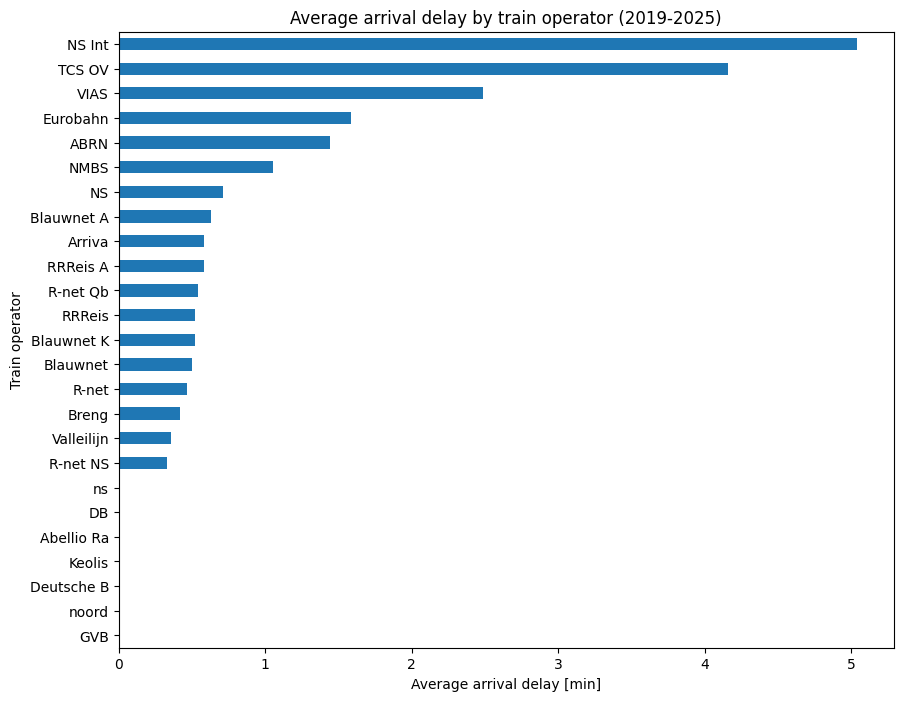

In [19]:
df_company_delays = db.sql("""
SELECT "Service:Company" AS company, AVG("Stop:Arrival delay") AS avg_arrival_delay
FROM services
WHERE "Stop:Arrival delay" IS NOT NULL
GROUP BY company
HAVING COUNT(*) >= 10000
ORDER BY avg_arrival_delay
""").df()

ax = df_company_delays.plot.barh(x="company", y="avg_arrival_delay", legend=False, figsize=(10, 8))
ax.set_title("Average arrival delay by train operator (2019-2025)")
ax.set_xlabel("Average arrival delay [min]")
ax.set_ylabel("Train operator")
plt.show()

### 7.8 How many services were disrupted in different years? Make a line plot.

In [20]:
df_disrupted_services = db.sql("""
WITH disruption_stations AS (
    SELECT TRIM(UNNEST(STRING_SPLIT(rdt_station_codes, ','))) AS station_code, start_time, end_time
    FROM postgres_db.disruptions
    WHERE YEAR(start_time) >= 2019
)
SELECT YEAR(s."Service:Date") AS year, COUNT(DISTINCT s."Service:RDT-ID") AS num_disrupted_services
FROM services AS s
JOIN disruption_stations AS d
  ON s."Stop:Station code" = d.station_code
 AND COALESCE(s."Stop:Departure time", s."Stop:Arrival time") BETWEEN d.start_time AND d.end_time
GROUP BY year
ORDER BY year
""").df()

df_disrupted_services

,year,num_disrupted_services
0,2019,272763
1,2020,265891
2,2021,293305
3,2022,435336
4,2023,458716


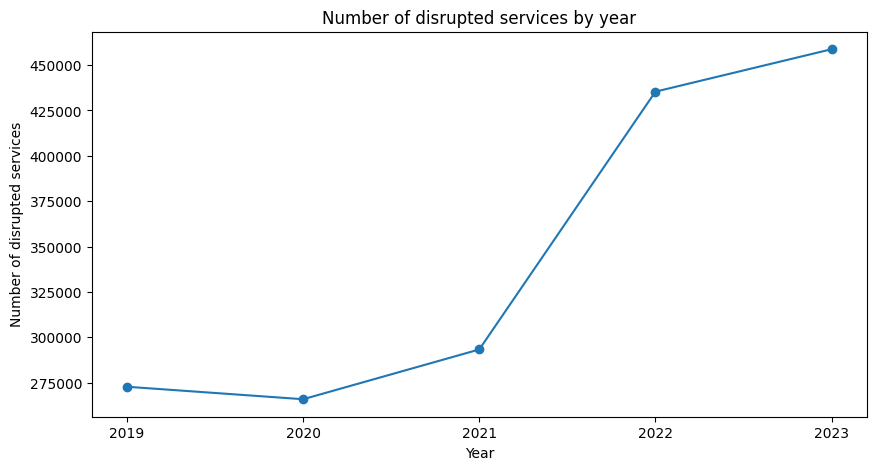

In [21]:
ax = df_disrupted_services.plot.line(x="year", y="num_disrupted_services", marker="o", legend=False, figsize=(10, 5))
ax.set_title("Number of disrupted services by year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of disrupted services")
ax.set_xticks(df_disrupted_services["year"])
plt.show()

### 7.9 What fraction of all services were cancelled (`Service:Completely cancelled`) in different years? Make a line plot.

In [22]:
df_cancelled = db.sql("""
SELECT YEAR("Service:Date") AS year,
       AVG("Service:Completely cancelled"::INT) AS fraction_cancelled
FROM (
    SELECT DISTINCT "Service:RDT-ID", "Service:Date", "Service:Completely cancelled"
    FROM services
)
GROUP BY year
ORDER BY year
""").df()

df_cancelled

,year,fraction_cancelled
0,2019,0.013212
1,2020,0.086580
2,2021,0.041762
3,2022,0.063572
4,2023,0.058378
5,2024,0.023109
6,2025,0.021683


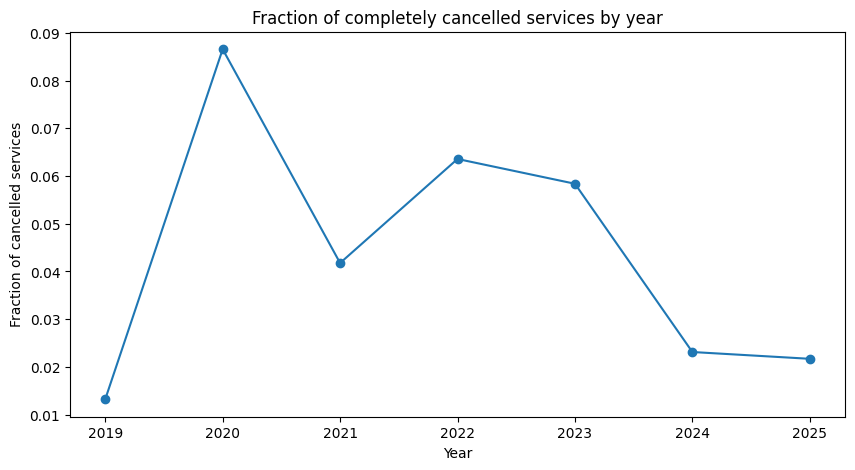

In [23]:
ax = df_cancelled.plot.line(x="year", y="fraction_cancelled", marker="o", legend=False, figsize=(10, 5))
ax.set_title("Fraction of completely cancelled services by year")
ax.set_xlabel("Year")
ax.set_ylabel("Fraction of cancelled services")
ax.set_xticks(df_cancelled["year"])
plt.show()

## 8. Prepare information about service lengths

### 8.1 Get the next station of a service using window functions

In [24]:
db.sql("""
SELECT "Service:RDT-ID",
       "Stop:Station code" AS start_station_code,
       LEAD("Stop:Station code") OVER (
           PARTITION BY "Service:RDT-ID"
           ORDER BY "Stop:Departure time" NULLS LAST
       ) AS end_station_code
FROM services
WHERE "Service:RDT-ID" = (SELECT MIN("Service:RDT-ID") FROM services)
ORDER BY "Stop:Departure time" NULLS LAST
""")

┌────────────────┬────────────────────┬──────────────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │
│     int64      │      varchar       │     varchar      │
├────────────────┼────────────────────┼──────────────────┤
│         738804 │ RTD                │ DT               │
│         738804 │ DT                 │ GV               │
│         738804 │ GV                 │ LEDN             │
│         738804 │ LEDN               │ SHL              │
│         738804 │ SHL                │ ASD              │
│         738804 │ ASD                │ UT               │
│         738804 │ UT                 │ NULL             │
└────────────────┴────────────────────┴──────────────────┘

### 8.2 Create table `station_connections`

In [25]:
db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH connections AS (
    SELECT "Service:RDT-ID",
           "Stop:Station code" AS start_station_code,
           LEAD("Stop:Station code") OVER (
               PARTITION BY "Service:RDT-ID"
               ORDER BY "Stop:Departure time" NULLS LAST
           ) AS end_station_code
    FROM services
)
SELECT DISTINCT ON (c.start_station_code, c.end_station_code)
       c."Service:RDT-ID", c.start_station_code, c.end_station_code, d.distance
FROM connections AS c
JOIN distances_long AS d
  ON c.start_station_code = d.station AND c.end_station_code = d.other_station
ORDER BY c.start_station_code, c.end_station_code
""")

db.sql("SELECT COUNT(*) FROM station_connections")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│         8799 │
└──────────────┘

In [26]:
db.sql("FROM station_connections LIMIT 10")

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│       13544556 │ AC                 │ AMFS             │       48 │
│        9757537 │ AC                 │ APN              │       50 │
│       13955559 │ AC                 │ ASA              │        9 │
│       17065180 │ AC                 │ ASB              │        5 │
│        9028069 │ AC                 │ ASD              │       15 │
│       10290982 │ AC                 │ ASDM             │       11 │
│         782343 │ AC                 │ ASHD             │        4 │
│        5894139 │ AC                 │ ASS              │       19 │
│       10751838 │ AC                 │ ASSP             │       12 │
│         768268 │ AC                 │ BKL              │       12 │
├────────────────┴──

### 8.3 What is the largest distance between a pair of stations?

In [27]:
db.sql("""
SELECT c.*, s1.name_long AS start_station_name, s2.name_long AS end_station_name
FROM station_connections AS c
JOIN stations AS s1 ON c.start_station_code = s1.code
JOIN stations AS s2 ON c.end_station_code = s2.code
ORDER BY c.distance DESC
LIMIT 1
""")

┌────────────────┬────────────────────┬──────────────────┬──────────┬────────────────────┬──────────────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │ start_station_name │ end_station_name │
│     int64      │      varchar       │     varchar      │  int64   │      varchar       │     varchar      │
├────────────────┼────────────────────┼──────────────────┼──────────┼────────────────────┼──────────────────┤
│        7123093 │ VS                 │ STV              │      421 │ Vlissingen         │ Stavoren         │
└────────────────┴────────────────────┴──────────────────┴──────────┴────────────────────┴──────────────────┘

In [28]:
db.sql("""
WITH longest AS (
    FROM station_connections
    ORDER BY distance DESC
    LIMIT 10
)
SELECT DISTINCT l.*, s."Service:Type"
FROM longest AS l
JOIN services AS s USING ("Service:RDT-ID")
ORDER BY l.distance DESC
""").df()

,Service:RDT-ID,start_station_code,end_station_code,distance,Service:Type
0,7123093,VS,STV,421,Stopbus i.p.v. trein
1,7123093,KMW,VS,417,Stopbus i.p.v. trein
2,7122512,VSS,HNP,411,Stopbus i.p.v. trein
3,7122512,WK,VSS,407,Stopbus i.p.v. trein
4,7122512,MDB,WK,402,Stopbus i.p.v. trein
5,7123093,VSS,SK,391,Stopbus i.p.v. trein
6,7122512,SK,MDB,386,Stopbus i.p.v. trein
7,7122512,GS,SK,367,Stopbus i.p.v. trein
8,7519474,LEER,DN,358,Stopbus i.p.v. trein
9,11353097,ASN,VS,353,Snelbus ipv trein


### 8.4 Plot a histogram of inter-station distances run by trains

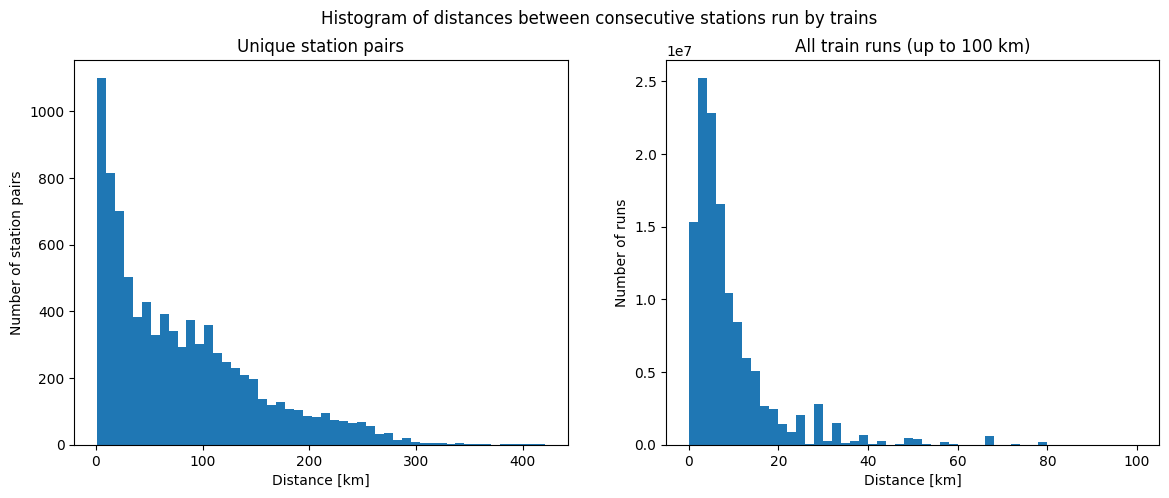

In [29]:
df_connections = db.sql("SELECT distance FROM station_connections").df()

df_runs = db.sql("""
WITH connections AS (
    SELECT "Stop:Station code" AS start_station_code,
           LEAD("Stop:Station code") OVER (
               PARTITION BY "Service:RDT-ID"
               ORDER BY "Stop:Departure time" NULLS LAST
           ) AS end_station_code
    FROM services
)
SELECT d.distance, COUNT(*) AS num_runs
FROM connections AS c
JOIN distances_long AS d
  ON c.start_station_code = d.station AND c.end_station_code = d.other_station
GROUP BY d.distance
""").df()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_connections["distance"], bins=50)
axes[0].set_title("Unique station pairs")
axes[0].set_xlabel("Distance [km]")
axes[0].set_ylabel("Number of station pairs")

axes[1].hist(df_runs["distance"], weights=df_runs["num_runs"], bins=range(0, 101, 2))
axes[1].set_title("All train runs (up to 100 km)")
axes[1].set_xlabel("Distance [km]")
axes[1].set_ylabel("Number of runs")

fig.suptitle("Histogram of distances between consecutive stations run by trains")
plt.show()

In [30]:
db.sql("DETACH postgres_db")
db.close()